# Simple Linear Regression From Scratch

## 1. Project Overview

The objective of this notebook is to understand and implement a **Simple Linear Regression model from scratch**, using Python and NumPy, without relying on machine learning libraries such as Scikit-learn.

Instead of simply using an existing implementation, we will build the model step by step to understand how linear regression works internally, how it learns its parameters, and how it makes predictions.

## 2. What Is Simple Linear Regression?

Simple Linear Regression is a supervised machine learning algorithm used to model the relationship between **one independent variable (X)** and **one dependent variable (Y)**.

It assumes that this relationship can be approximated by a straight line:

\[
\$\hat{y}$ = $\beta_0$ + $\beta_1x$
\]

Where:

- \($x$\): Independent variable (input feature).
- \($\hat{y}$\): Predicted value.
- \($\beta_0$\): Intercept (the value of Y when X = 0).
- \($\beta_1$\): Slope (how much Y changes when X increases by one unit).

## 3. Mathematical Objective

The main objective is to find the optimal values of the parameters \($\beta_0$\) and \($\beta_1$\) that minimize the difference between actual values and predicted values.

We will use the **Ordinary Least Squares (OLS)** approach, which minimizes the Sum of Squared Errors:

\[$
SSE = \sum_{i=1}^{n}(y_i - \hat{y}_i)^2$
\]

By minimizing this function, we obtain the line that best fits our training data.

## 4. Implementation Roadmap

We will build our model through the following steps:

1. **Import Libraries:** Import NumPy, Pandas, and Matplotlib for numerical operations, data manipulation, and visualization.
2. **Create or Load Dataset:** Prepare a simple dataset containing one independent variable and one target variable.
3. **Exploratory Data Analysis:** Visualize the relationship between X and Y using a scatter plot.
4. **Implement Linear Regression:** Calculate the slope and intercept using mathematical formulas.
5. **Make Predictions:** Use the learned parameters to predict new values.
6. **Evaluate the Model:** Measure model performance using:
   - Mean Squared Error (MSE)
   - Root Mean Squared Error (RMSE)
   - R-squared (\(R^2\))
7. **Visualize Results:** Plot the original observations and the regression line to evaluate how well the model fits the data.

## 5. Expected Outcome

By the end of this notebook, we should be able to:

- Understand the mathematical foundations of Linear Regression.
- Implement a regression model without Scikit-learn.
- Understand how the slope and intercept are calculated.
- Make predictions using the trained model.
- Evaluate and interpret regression performance metrics.
- Understand the relationship between residuals, prediction errors, and the regression line.

---

**Note:** The purpose of this project is not just to obtain a working model, but to understand the mathematics and logic behind Linear Regression.

In [22]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

cwd = Path.cwd()
root = cwd.parent
data_dir = root / "Datasets" / "Simple-linear-regression"

df = pd.read_csv(data_dir / "Salary_dataset.csv")

print(df.info())
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       30 non-null     int64  
 1   YearsExperience  30 non-null     float64
 2   Salary           30 non-null     float64
dtypes: float64(2), int64(1)
memory usage: 852.0 bytes
None


,Unnamed: 0,YearsExperience,Salary
count,30.000000,30.000000,30.000000
mean,14.500000,5.413333,76004.000000
std,8.803408,2.837888,27414.429785
min,0.000000,1.200000,37732.000000
25%,7.250000,3.300000,56721.750000
50%,14.500000,4.800000,65238.000000
75%,21.750000,7.800000,100545.750000
max,29.000000,10.600000,122392.000000


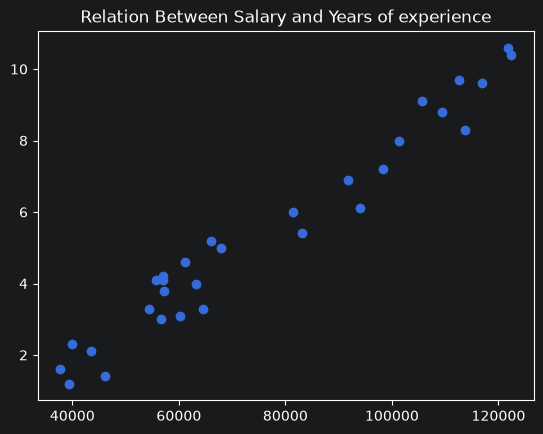

In [6]:
# df = df.drop(columns=["Unnamed: 0"])

y = df["Salary"]
X = df["YearsExperience"]

plt.scatter(y,X)
plt.title("Relation Between Salary and Years of experience")
plt.show()

## \$Correlation\ = \frac{\sum_{i=0}^{n}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=0}^{n}(x_i - \bar{x})^2} \sqrt{\sum_{i=0}^{n}(y_i - \bar{y})^2}}$

In [17]:
sum1 = sum((X-X.mean())*(y-y.mean()))
sum2 = np.sqrt(sum((X-X.mean())**2))
sum3 = np.sqrt(sum((y-y.mean())**2))

corr = sum1 / (sum2 * sum3)

print(round(corr,2))

0.98


In [18]:
W = (sum((X - X.mean()) * (y - y.mean()))) / sum((X - X.mean())**2)
B = y.mean() - (np.dot(W,X.mean()))

9449.962321455077
24848.203966523193


In [21]:
y_predict = np.dot(X,W) + B

RSS = sum((y - y_predict)**2)

RSE = np.sqrt(RSS / (len(df) - 2))
TSS = sum((y - y.mean())**2)

R2 = 1 - (RSS/TSS)

print(f"RSS : {RSS}")
print(f"RSE : {RSE}")
print(f"TSS : {TSS}")
print(f"R2 : {R2}")

RSS : 938128551.6684288
RSE : 5788.3150511193935
TSS : 21794977852.0
R2 : 0.9569566641435086


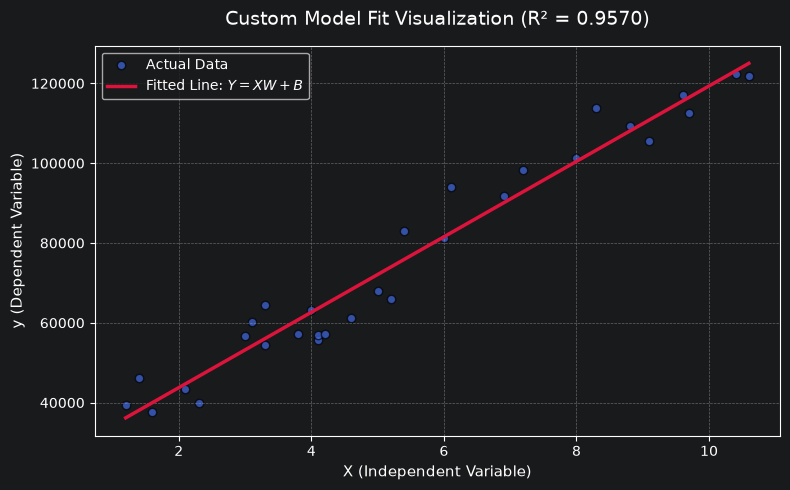

In [24]:
# sns.regplot(x=X, y=y, scatter_kws={'color': 'royalblue', 'alpha':0.7}, line_kws={'color': 'crimson'})
#
# plt.title('Automatic Regression Plot with Seaborn')
# plt.show()

X_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)

# 2. Use your exact model equation to calculate the line's Y values
y_line = np.dot(X_line, W) + B

# 3. Plot the original observations and your custom fitted line
plt.figure(figsize=(8, 5))

# Plot actual data points (flatten X if it's a 2D column vector)
plt.scatter(X.flatten() if X.ndim > 1 else X, y, color='royalblue', alpha=0.7, edgecolors='k', label='Actual Data')

# Plot your custom regression line
plt.plot(X_line, y_line, color='crimson', linewidth=2.5, label='Fitted Line: $Y = XW + B$')

# Labeling and styling
plt.title(f'Custom Model Fit Visualization (R² = {R2:.4f})', fontsize=14, pad=15)
plt.xlabel('X (Independent Variable)', fontsize=11)
plt.ylabel('y (Dependent Variable)', fontsize=11)
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()